# Descriptive implementation of image fuzzyfication 

Importing L

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

Reading Image

In [2]:
img = cv2.imread("sc_img.jpg", cv2.COLOR_BGR2GRAY)

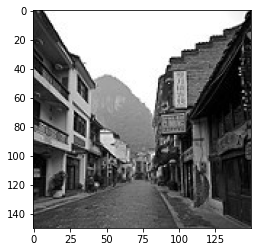

In [3]:
plt.imshow(img, cmap = 'gray')

Membership Function 

In [46]:
def smf(x, a, b):

    if x <= a:
        return 0

    elif a < x <= (a + b) / 2:
        return 2 * ((x - a) / (b - a))**2

    elif (a + b) / 2 < x <= b:
        return 1 - 2 * ((x - b) / (b - a))**2

    else:
        return 1

In [47]:
new = []
for i in img:
    row = []
    for j in i:
        row.append(smf(j,50,200))
    new.append(row)

In [48]:
new = np.array(new)

Intnsityfication 

In [49]:
def intensityf(pixel):
    if pixel >0.5:
        return (1-(2*((1-pixel)**2)))
    else:
        return (2*(pixel**2))

In [50]:
inten = []
for i in new:
    row = []
    for j in i:
        row.append(intensityf(j))
    inten.append(row)    
inten = np.array(inten)

Defuzzyfication 

In [51]:
inten = inten*255

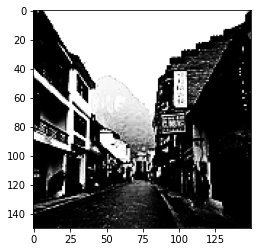

In [52]:
plt.imshow(inten, cmap='gray')

# Using new membership function 

In [41]:
def new_mf(i):
    return (255-i)/255

In [42]:
new = []
for i in img:
    row = []
    for j in i:
        row.append(new_mf(j))
    new.append(row)
new = np.array(new)

In [43]:
inten = []
for i in new:
    row = []
    for j in i:
        row.append(intensityf(j))
    inten.append(row)    
inten = np.array(inten)

In [44]:
inten = 255*(1-inten)

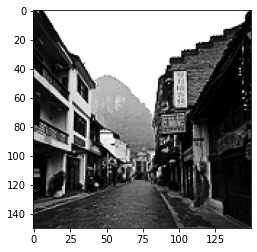

In [45]:
plt.imshow(inten, cmap='gray')